# 05 — 적합도 예측 신뢰도 (`results/conf_fitpred`)

회귀 모델 출력 $\mu$ (`fitness_z`) · $\sigma$ (`fitness_sd`) 를 실측과 맞을 확률로 바꾸는 확률표 2개를, 서비스 회귀 모델과 같은 입력 조합(`fitpred_ablation/noseq`)의 교차검증 예측으로 만든다. `conf_ess` 보정은 03 · 04 분류 노트북이 각 결과 폴더에서 한다.

| 신뢰도 | 정의 | 보정 입력 | 보정 전 |
|---|---|---|---|
| `conf_sign` | 실측 적합도가 예측과 같은 쪽(균주 평균보다 높음 / 낮음)에 있을 확률 | $(\mu,\ \log\sigma)$ | $\Phi(\lvert\mu\rvert / \sigma)$ |
| `conf_fit` | 실측 적합도가 $\mu \pm \sigma$ 안에 있을 확률 | $(\mu,\ \log\sigma)$ | 0.683 |

- 실측 적합도 = 균주 내 z-정규화 `fit_mean`

| 파일 (`results/conf_fitpred/`) | 내용 |
|---|---|
| `conf_*/fold##_<genus>/inner##/` | `model_calib.pkl` · `pred_calib.npz` (`best_epoch` · 확률표 `table` · 시험 확률 `prob`, 있으면 다시 학습하지 않고 읽는다) · `metrics_organ_calib.csv` · `calibration.png` |
| `conf_*/fold##_<genus>/metrics_folds_calib.csv` | 내부 폴드별 1줄 + mean · median · std 줄 |
| `conf_*/metrics_total_calib.csv` | genus별 보정 후 성능 (마지막 3줄 = genus 간 mean · median · std) |
| `conf_*/compare_calib.csv` · `check_calib.csv` · `calibration.png` | 보정 전 · 후 genus 평균 · 표준편차 · 확률 구간별 표 · 그림 |
| `conf_*/model_final_calib.pkl` | 최종 모델 (28 genus 전체) |
| `calibration.json` | 최종 확률표 2개 (격자 · 확률 · 반복 수), 서비스 `assets/` 로 복사 |
| `calibration.png` | 보정 그림 (위 행 보정 전, 아래 행 보정 후) |

진행: 1 데이터 → 2 보정 대상 → 3 확률표 → 4 중첩 교차검증 → 5 보정 전 · 후 비교 → 6 최종 확률표

In [1]:
import os, json
import numpy as np, pandas as pd
from proteomefit import calib, data
from proteomefit.config import Config
from proteomefit.plots import reliability_plot

cfg     = Config()                                    # base data 경로
SRC_DIR = '../results/fitpred_ablation/noseq'          # 보정 자료 (서비스 회귀 모델 입력 조합의 교차검증 결과)
OUT_DIR = '../results/conf_fitpred'
NAMES   = ('sign', 'fit')
os.makedirs(OUT_DIR, exist_ok=True)

## 1. 데이터 — 교차검증 예측과 라벨

| 표 | 형태 | 열 |
|---|---|---|
| `R` | `[531,951]` | `mu` · `sd` · `y` 실측 (균주 내 z) · `org` · `genus` · `inner` 원 모델 내부 폴드 |

- 예측 = `SRC_DIR/fold##_<genus>/inner##/pred.npz` (외부 폴드 28 x 내부 폴드 3, 유전자마다 3개)
- `VAL` = genus별 원 모델의 내부 검증 genus 3개 (`metrics_total.csv` 의 `val_genera`)

In [2]:
# 적합도 수치가 있는 샘플 [n_reg] -> 예측 표 [n_pred, 6] (mu, sd, y, org, genus, inner)
D   = data.load_samples(cfg.base_dir, cfg.label_col, finite_only=True)
R   = calib.load_cv_preds(SRC_DIR, {'y': data.fit_labels(D), 'org': D.org}, D.gen)
VAL = calib.val_genera(SRC_DIR)
print(f"regression predictions: {len(R):,} | median |mu| {R.mu.abs().median():.3f} | median sd {R.sd.median():.3f}")
print('validation genera (first fold):', next(iter(VAL.items())))

regression predictions: 531,951 | median |mu| 0.456 | median sd 0.530
validation genera (first fold): ('Pseudomonas', ['Acidovorax', 'Desulfovibrio', 'Marinobacter'])


## 2. 보정 대상 — 입력 · 적중 · 보정 전 확률

| 신뢰도 | 입력 `X` | 적중 `hit` | 보정 전 `before` |
|---|---|---|---|
| `conf_sign` | $(\mu,\ \log\sigma)$ `[m, 2]` | $\mathrm{sign}(y) = \mathrm{sign}(\mu)$ | $\Phi(\lvert\mu\rvert / \sigma)$ |
| `conf_fit` | $(\mu,\ \log\sigma)$ `[m, 2]` | $\mu - \sigma \le y \le \mu + \sigma$ | 0.683 |

In [3]:
for name in NAMES:
    X, hit, before = calib.calib_target(name, R)                       # [m, 2] · [m] · [m]
    print(f'conf_{name}: X {X.shape} | hit rate {hit.mean():.3f} | mean before {before.mean():.3f}')

conf_sign: X (531951, 2) | hit rate 0.595 | mean before 0.792
conf_fit: X (531951, 2) | hit rate 0.538 | mean before 0.683


## 3. 확률표 — 기울기 부스팅

| 단계 | 내용 | 형태 |
|---|---|---|
| 학습 | `HistGradientBoostingClassifier` 로 입력 `X` → 적중 여부 분류 (반복 수 고정) | `[m, 2]` |
| 확률표 | 격자 `calib.AXES` 위 예측 확률 | `[101, 29]` |
| 적용 | 확률표 선형 보간 (격자 밖은 가장자리 값) | `[n]` |

- 반복 수 = 검증 genus 로그 손실이 가장 작은 반복 수 (`staged_predict_proba`)
- 설정 · 함수 = `proteomefit/calib.py`, 지표 = `proteomefit/metrics.py`, 그림 = `proteomefit/plots.py`
- 아래 셀 = `conf_fit` 외부 폴드 1 · 내부 폴드 1 의 학습 · 반복 수 선택 · 확률표

In [4]:
G, vs = next(iter(VAL.items()))
X, hit, _ = calib.calib_target('fit', R)
gen   = R.genus.values
tr    = (gen != G) & (gen != vs[0])
model = calib.fit_hgb(X[tr], hit[tr], calib.MAX_ITER, calib.MONO['fit'])
b     = calib.best_epoch(model, X[gen == vs[0]], hit[gen == vs[0]])
T     = calib.staged_tables(model, calib.AXES['fit'])                  # 반복 수별 확률표 [300, 101, 29]
x     = np.array([[-1.0, np.log(0.5)]])                                 # mu = -1.0, sd = 0.5
print(f'test {G} | val {vs[0]} | best iteration {b} | tables {T.shape}')
print('conf_fit(mu=-1.0, sd=0.5) at iteration 1 / best / 300:',
      [round(float(calib.lookup(T[i], calib.AXES['fit'], x)[0]), 3) for i in (0, b - 1, calib.MAX_ITER - 1)])

test Pseudomonas | val Acidovorax | best iteration 35 | tables (300, 101, 29)
conf_fit(mu=-1.0, sd=0.5) at iteration 1 / best / 300: [0.519, 0.186, 0.132]


## 4. 중첩 교차검증

| 단계 | 학습 | 검증 | 시험 |
|---|---|---|---|
| 외부 폴드 $k$ (28) | — | — | genus $k$ 의 예측 |
| 내부 폴드 $j$ (3) | $k$ · $v_j$ 를 뺀 26 genus 의 예측 | 원 모델 내부 폴드 $j$ 의 검증 genus $v_j$ → 최적 반복 수 $b_{kj}$ | $b_{kj}$ 의 확률표를 genus $k$ 의 원 모델 내부 폴드 $j$ 예측에 적용 |
| 최종 | 28 genus 전체 | — | 반복 수 = $\mathrm{median}_k\ \mathrm{median}_j\ b_{kj}$ |

- genus 성능 = 내부 폴드 3개 지표의 평균 · 표준편차, 내부 폴드 지표 = 균주별 지표의 평균
- 표의 분할 열(`val_genus` · `val_sim` · `val_nn`)은 원 모델 `metrics_folds.csv` 에서 가져오고, 반복 수 = `best_epoch`, 검증 지표 = `val_log_loss`

| 지표 | 내용 | 좋은 방향 |
|---|---|---|
| `ece` | 확률 구간 10개의 \|예측 확률 평균 − 실제 비율\| 구간 크기 가중 평균 | 0 |
| `brier` | $(p - \text{적중})^2$ 의 평균 | 0 |
| `log_loss` | $-\log$ (실제 결과에 준 확률) 의 평균 | 0 |
| `roc_auc` | 적중 · 빗나감의 확률 순위 구별력 | 1 |

In [5]:
RES, CMP, CHECK = {}, {}, {}                                           # genus별 보정 후 결과 · 보정 전 · 후 비교 · 확률 구간별 표
for name in NAMES:
    RES[name], CMP[name], CHECK[name] = calib.nested_cv(name, R, SRC_DIR, f'{OUT_DIR}/conf_{name}')
    print()

conf_sign fold  1 Pseudomonas      best@ 13.0 | val_log_loss 0.657 | ece 0.208 -> 0.048 | brier 0.292 -> 0.236
conf_sign fold  2 Ralstonia        best@  9.0 | val_log_loss 0.668 | ece 0.244 -> 0.043 | brier 0.315 -> 0.243
conf_sign fold  3 Shewanella       best@ 48.0 | val_log_loss 0.645 | ece 0.177 -> 0.115 | brier 0.274 -> 0.213
conf_sign fold  4 Dickeya          best@  9.0 | val_log_loss 0.681 | ece 0.167 -> 0.069 | brier 0.264 -> 0.225
conf_sign fold  5 Cupriavidus      best@ 10.0 | val_log_loss 0.668 | ece 0.247 -> 0.048 | brier 0.321 -> 0.246
conf_sign fold  6 Burkholderia     best@ 17.0 | val_log_loss 0.670 | ece 0.219 -> 0.050 | brier 0.303 -> 0.245
conf_sign fold  7 Desulfovibrio    best@ 14.0 | val_log_loss 0.663 | ece 0.162 -> 0.041 | brier 0.266 -> 0.226
conf_sign fold  8 Paraburkholderia best@ 19.0 | val_log_loss 0.670 | ece 0.170 -> 0.058 | brier 0.271 -> 0.220
conf_sign fold  9 Sinorhizobium    best@ 63.0 | val_log_loss 0.637 | ece 0.230 -> 0.050 | brier 0.314 -> 0.247
c

## 5. 보정 전 · 후 비교

- `compare_calib.csv` = 지표별 genus 28개 값의 평균 · 표준편차 (보정 전 · 후). 최종 성능 = 보정 후 평균
- `check_calib.csv` = 시험 예측 전체를 확률 구간으로 나눈 표

| 열 | 내용 |
|---|---|
| `stage` | `before` (보정 전) · `after` (보정 후) |
| `bin` | 그 단계 확률의 구간 |
| `n` | 구간 안 예측 수 |
| `predicted` · `observed` | 구간 안 확률 평균 · 실제 적중 비율 |

- 그림 = 위 행 보정 전, 아래 행 보정 후, 구간마다 원 하나 (가로 = 실제 비율, 세로 = 예측 확률, 넓이 = 예측 비율, 범례 = n). 대각선 위 = 보정이 맞음. 패널 제목 아래 = genus 평균 ECE · Brier · 로그 손실

conf_sign (genus mean, before -> after)
  metric  before  before_sd  after  after_sd
     ece   0.190      0.049  0.061     0.038
   brier   0.284      0.032  0.229     0.016
log_loss   0.919      0.128  0.650     0.034
 roc_auc   0.554      0.025  0.622     0.063 

 stage        bin      n  predicted  observed
before (0.5, 0.6]  69829      0.551     0.517
before (0.6, 0.7]  79816      0.651     0.549
before (0.7, 0.8]  98756      0.752     0.586
before (0.8, 0.9] 130886      0.852     0.619
before (0.9, 1.0] 152664      0.951     0.639
 after (0.3, 0.4]  17737      0.381     0.388
 after (0.4, 0.5]  85695      0.451     0.416
 after (0.5, 0.6]  57197      0.547     0.529
 after (0.6, 0.7] 360281      0.643     0.655
 after (0.7, 0.8]  10989      0.717     0.689
 after (0.8, 0.9]     52      0.805     0.673 

conf_fit (genus mean, before -> after)
  metric  before  before_sd  after  after_sd
     ece   0.140      0.062  0.067     0.033
   brier   0.265      0.026  0.211     0.019
log_l

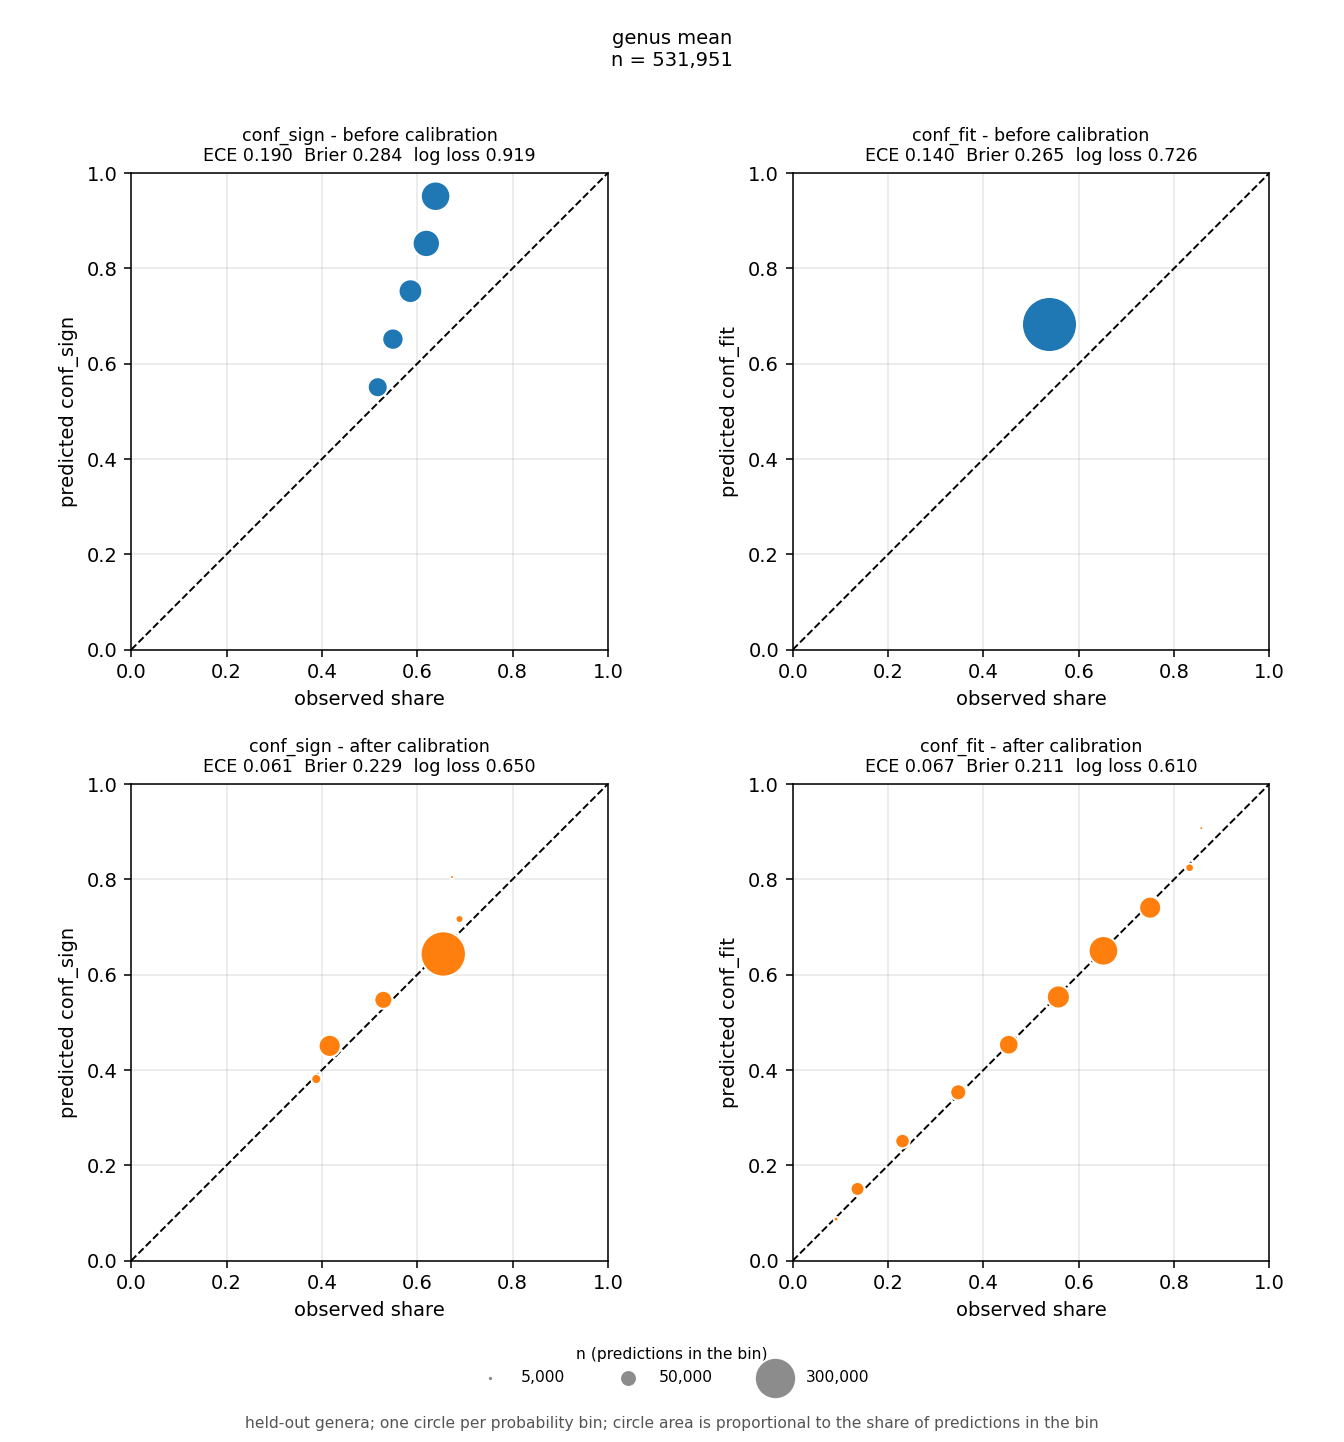

In [6]:
for name in NAMES:
    print(f'conf_{name} (genus mean, before -> after)'); print(CMP[name].round(3).to_string(index=False), '\n')
    print(CHECK[name].round(3).to_string(index=False), '\n')
note = lambda c, st: '  '.join(f'{k} {c.set_index("metric").loc[m, st]:.3f}' for k, m in (('ECE', 'ece'), ('Brier', 'brier'), ('log loss', 'log_loss')))
reliability_plot({f'conf_{n}': CHECK[n] for n in NAMES}, f'{OUT_DIR}/calibration.png', 'genus mean',
                 {f'conf_{n}': {st: note(CMP[n], st) for st in ('before', 'after')} for n in NAMES})   # 패널 지표 = genus 평균

## 6. 최종 확률표

28 genus 전체 예측으로 최종 모델(`conf_*/model_final_calib.pkl`)을 학습하고, 그 확률표를 `calibration.json` 에 저장한다.

| 키 | 내용 |
|---|---|
| `sign` · `fit` | `axes` (격자 축 목록) · `p` (확률표) · `n_iter` (반복 수) · `source` (보정 자료) |

In [7]:
cal = {n: {**calib.final_model(n, R, RES[n], f'{OUT_DIR}/conf_{n}'), 'source': SRC_DIR.split('results/')[1]} for n in NAMES}
with open(f'{OUT_DIR}/calibration.json', 'w', encoding='utf-8') as f:
    json.dump(cal, f)
for n in NAMES:
    print(f"conf_{n}: final iterations {cal[n]['n_iter']} | range {np.min(cal[n]['p']):.3f} - {np.max(cal[n]['p']):.3f}")

# 예시 - 예측 평균 · 표준편차별 두 확률
ex = pd.DataFrame({'mu': [0.1, 0.6, -0.5, -1.0, -2.0, -4.0], 'sd': [0.5, 0.4, 0.5, 0.5, 0.6, 1.0]})
for n in NAMES:
    ex[f'conf_{n}'] = calib.lookup(np.array(cal[n]['p']), calib.AXES[n], np.column_stack([ex.mu, np.log(ex.sd)]))
print(ex.round(2).to_string(index=False))
print(f'\nsaved {OUT_DIR}/calibration.json | calibration.png | conf_*/')

conf_sign: final iterations 18 | range 0.394 - 0.736
conf_fit: final iterations 64 | range 0.067 - 0.899
  mu  sd  conf_sign  conf_fit
 0.1 0.5       0.63      0.70
 0.6 0.4       0.65      0.42
-0.5 0.5       0.43      0.32
-1.0 0.5       0.48      0.14
-2.0 0.6       0.58      0.09
-4.0 1.0       0.66      0.11

saved ../results/conf_fitpred/calibration.json | calibration.png | conf_*/
